# P16B — Pengantar deep learning: MLP pada data tabular dan CNN pada citra
Latihan ini memperkenalkan *deep learning* lewat dua contoh kecil yang dapat dijalankan di CPU. Bagian 1–2 melatih jaringan saraf berlapis (*multilayer perceptron*, MLP) untuk memprediksi kuat tekan beton sintesis dari Bab 3 dan membandingkannya dengan model klasik. Bagian 3 melatih jaringan konvolusi (*convolutional neural network*, CNN) untuk mengenali retak pada citra sintetis dari P16A.

**Urutan kerja.** Jalankan P16A lebih dulu. Seluruh angka berasal dari data sintetis dan *seed* 16016; angka dapat berbeda pada digit kedua bila versi PyTorch atau perangkat berbeda, tanpa mengubah kesimpulan kualitatif.


In [1]:
import time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

SEED = 16016
torch.set_num_threads(1)
print("PyTorch", torch.__version__)

def cari(nama):
    for p in (Path(nama), Path(nama).name, Path("data_bab16") / Path(nama).name):
        if Path(p).exists(): return Path(p)
    raise FileNotFoundError(f"{nama} tidak ditemukan; jalankan P16A (citra) atau buka dari akar repositori.")

PyTorch 2.15.0+cpu


## 1. Data tabular dan model pembanding
Data kuat tekan beton sintesis (1.200 baris) dibagi menjadi data latih, validasi, dan uji. Skala fitur dipelajari dari data latih saja. Baseline rerata, regresi linear, dan Random Forest menjadi pembanding sebelum jaringan saraf dicoba.


In [2]:
df = pd.read_csv(cari("praktikum/bab03/data_sintesis_beton.csv"))
fitur = [c for c in df.columns if c not in ("id_spesimen", "kuat_tekan_MPa")]
X, y = df[fitur].to_numpy(float), df["kuat_tekan_MPa"].to_numpy(float)
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=SEED)
sc = StandardScaler().fit(X_tr)                       # statistik skala hanya dari data latih
Xs_tr, Xs_va, Xs_te = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)
ym, ys = y_tr.mean(), y_tr.std()
print("latih/validasi/uji:", len(y_tr), len(y_va), len(y_te), "| fitur:", len(fitur))

def metrik(yt, yp):
    return {"MAE": mean_absolute_error(yt, yp), "RMSE": root_mean_squared_error(yt, yp), "R2": r2_score(yt, yp)}

latih/validasi/uji: 720 240 240 | fitur: 8


In [3]:
hasil = {"Baseline rerata": metrik(y_te, np.full_like(y_te, y_tr.mean()))}
t0 = time.perf_counter(); lin = LinearRegression().fit(X_tr, y_tr); hasil["Regresi linear"] = metrik(y_te, lin.predict(X_te)) | {"detik": time.perf_counter()-t0}
t0 = time.perf_counter(); rf = RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED).fit(X_tr, y_tr)
hasil["Random Forest"] = metrik(y_te, rf.predict(X_te)) | {"detik": time.perf_counter()-t0}
print(pd.DataFrame(hasil).T.round(3))

                   MAE   RMSE     R2  detik
Baseline rerata  7.879  9.470 -0.001    NaN
Regresi linear   2.390  2.995  0.900  0.002
Random Forest    3.245  4.019  0.820  0.511


## 2. MLP dengan PyTorch
Jaringan 8-32-32-1 dilatih dengan Adam dan galat kuadrat. Data validasi dipakai untuk *early stopping*: pelatihan dihentikan bila galat validasi tidak membaik selama 30 epoch, lalu bobot terbaik dipulihkan.


In [4]:
def bangun_mlp(d_in, hidden, dropout=0.0):
    lap, d = [], d_in
    for h in hidden:
        lap += [nn.Linear(d, h), nn.ReLU()] + ([nn.Dropout(dropout)] if dropout > 0 else [])
        d = h
    return nn.Sequential(*lap, nn.Linear(d, 1))

def latih_mlp(Xtr, ytr, Xva, yva, seed, hidden=(32, 32), lr=1e-2, wd=0.0, dropout=0.0,
              max_epoch=400, sabar=30, batch=64):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    net = bangun_mlp(Xtr.shape[1], hidden, dropout)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd); rugi = nn.MSELoss()
    T = lambda a: torch.tensor(a, dtype=torch.float32).view(len(a), -1)
    xt, yt, xv, yv = T(Xtr), T((ytr-ym)/ys), T(Xva), T((yva-ym)/ys)
    terbaik, state, buruk, riwayat = np.inf, None, 0, []
    for ep in range(max_epoch):
        net.train(); perm = torch.randperm(len(xt), generator=g)
        for i in range(0, len(xt), batch):
            idx = perm[i:i+batch]; opt.zero_grad(); rugi(net(xt[idx]), yt[idx]).backward(); opt.step()
        net.eval()
        with torch.no_grad(): rt, rv = rugi(net(xt), yt).item(), rugi(net(xv), yv).item()
        riwayat.append((rt, rv))
        if rv < terbaik - 1e-5: terbaik, buruk, state = rv, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else: buruk += 1
        if sabar and buruk >= sabar: break
    if sabar: net.load_state_dict(state)
    return net, np.array(riwayat)

def prediksi(net, Xa):
    net.eval()
    with torch.no_grad(): return net(torch.tensor(Xa, dtype=torch.float32)).numpy().ravel()*ys + ym

t0 = time.perf_counter()
net, riw = latih_mlp(Xs_tr, y_tr, Xs_va, y_va, SEED)
detik = time.perf_counter()-t0
n_param = sum(p.numel() for p in net.parameters())
print(f"MLP 8-32-32-1: {n_param} parameter | epoch dijalankan: {len(riw)} | epoch terbaik: {riw[:,1].argmin()+1}")
hasil["MLP (standardisasi, early stopping)"] = metrik(y_te, prediksi(net, Xs_te)) | {"detik": detik}

MLP 8-32-32-1: 1377 parameter | epoch dijalankan: 41 | epoch terbaik: 11


Dua variasi berikut menunjukkan akibat praktik yang buruk: fitur tanpa standardisasi, dan jaringan besar yang dilatih tanpa *early stopping*.


In [5]:
net_raw, riw_raw = latih_mlp(X_tr, y_tr, X_va, y_va, SEED)
hasil["MLP tanpa standardisasi"] = metrik(y_te, prediksi(net_raw, X_te))
net_besar, riw_besar = latih_mlp(Xs_tr, y_tr, Xs_va, y_va, SEED, hidden=(256, 256), sabar=0, max_epoch=300)
hasil["MLP 256-256 tanpa early stopping"] = metrik(y_te, prediksi(net_besar, Xs_te))
print(pd.DataFrame(hasil).T.round(3))

                                       MAE   RMSE     R2  detik
Baseline rerata                      7.879  9.470 -0.001    NaN
Regresi linear                       2.390  2.995  0.900  0.002
Random Forest                        3.245  4.019  0.820  0.511
MLP (standardisasi, early stopping)  2.443  3.081  0.894  1.031
MLP tanpa standardisasi              2.635  3.276  0.880    NaN
MLP 256-256 tanpa early stopping     3.046  3.779  0.841    NaN


Kurva pelatihan memperlihatkan selisih galat latih dan validasi.


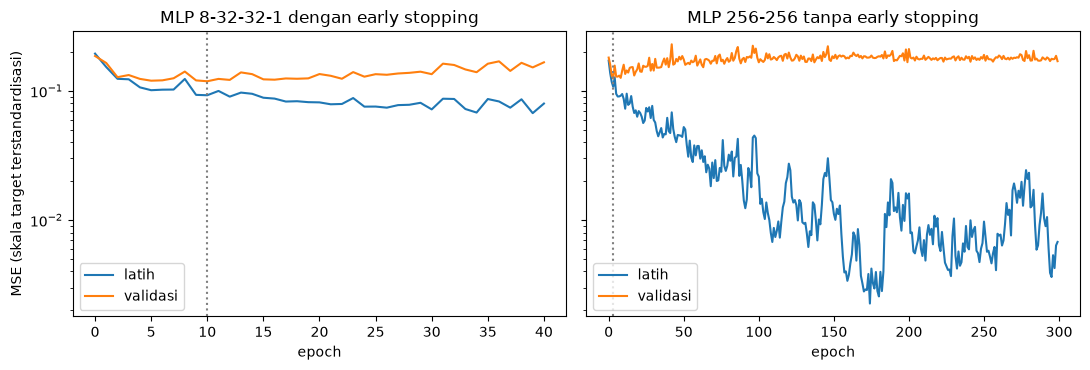

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, r, jd in ((ax[0], riw, "MLP 8-32-32-1 dengan early stopping"), (ax[1], riw_besar, "MLP 256-256 tanpa early stopping")):
    a.plot(r[:, 0], label="latih"); a.plot(r[:, 1], label="validasi"); a.set(title=jd, xlabel="epoch"); a.legend()
    a.axvline(r[:, 1].argmin(), color="gray", ls=":")
ax[0].set_ylabel("MSE (skala target terstandardisasi)"); ax[0].set_yscale("log")
plt.tight_layout(); plt.show()

Jaringan saraf bergantung pada nilai awal bobot dan urutan mini-batch. Lima benih acak menunjukkan besar variasi itu.


In [7]:
hs = []
for s in range(5):
    n_, _ = latih_mlp(Xs_tr, y_tr, Xs_va, y_va, SEED+s); hs.append(metrik(y_te, prediksi(n_, Xs_te)))
hs = pd.DataFrame(hs); print("MLP, 5 benih acak (rerata ± simpangan baku):"); print(pd.DataFrame({"rerata": hs.mean(), "sd": hs.std()}).round(3))

MLP, 5 benih acak (rerata ± simpangan baku):
      rerata     sd
MAE    2.465  0.041
RMSE   3.079  0.058
R2     0.894  0.004


## 3. CNN untuk citra retak sintetis
Citra dibagi menurut **panel**: seluruh citra satu panel masuk ke satu bagian saja, sehingga citra uji berasal dari panel yang belum pernah dilihat model.


In [8]:
d = np.load(cari("praktikum/bab16/citra_retak_sintetis.npz"))
Xi, yi, panel = d["X"].astype("float32")/255.0, d["y"].astype(int), d["panel"]
g1 = GroupShuffleSplit(1, test_size=0.20, random_state=SEED); a, te = next(g1.split(Xi, yi, panel))
g2 = GroupShuffleSplit(1, test_size=0.25, random_state=SEED); b, c = next(g2.split(Xi[a], yi[a], panel[a]))
tr, va = a[b], a[c]
print("citra latih/validasi/uji:", len(tr), len(va), len(te), "| panel per bagian:",
      len(set(panel[tr])), len(set(panel[va])), len(set(panel[te])), "| tumpang tindih panel latih-uji:", len(set(panel[tr]) & set(panel[te])))
mu, sd = Xi[tr].mean(), Xi[tr].std()
Z = (Xi - mu)/sd

citra latih/validasi/uji: 1440 480 480 | panel per bagian: 36 12 12 | tumpang tindih panel latih-uji: 0


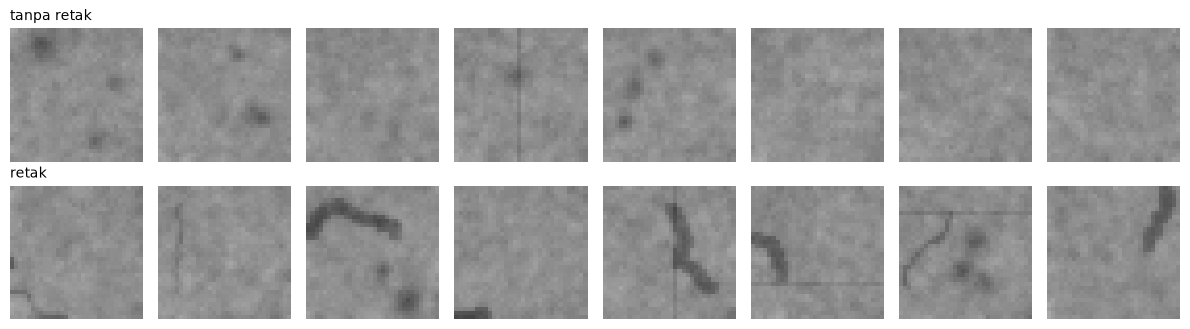

In [9]:
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for r, k in enumerate((0, 1)):
    for a_, i in zip(ax[r], tr[yi[tr] == k][:8]):
        a_.imshow(d["X"][i], cmap="gray", vmin=0, vmax=255); a_.axis("off")
    ax[r, 0].set_title("tanpa retak" if k == 0 else "retak", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

CNN dan MLP piksel dibuat dengan jumlah parameter yang hampir sama agar perbandingannya adil. Perbedaannya ada pada cara lapisan pertama memakai struktur citra.


In [10]:
class CNNKecil(nn.Module):
    def __init__(self):
        super().__init__()
        self.fitur = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                   nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.kepala = nn.Sequential(nn.Flatten(), nn.Linear(16*8*8, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x): return self.kepala(self.fitur(x))

def mlp_piksel(): return nn.Sequential(nn.Flatten(), nn.Linear(32*32, 32), nn.ReLU(), nn.Linear(32, 1))
jumlah = lambda m: sum(p.numel() for p in m.parameters())
print("parameter CNN:", jumlah(CNNKecil()), "| parameter MLP piksel:", jumlah(mlp_piksel()))

def latih_klasifikasi(buat, idx_tr, idx_va, seed, lr=3e-3, max_epoch=40, sabar=6, batch=64):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    net = buat(); opt = torch.optim.Adam(net.parameters(), lr=lr); rugi = nn.BCEWithLogitsLoss()
    T = lambda i: torch.tensor(Z[i][:, None], dtype=torch.float32)
    xt, yt, xv, yv = T(idx_tr), torch.tensor(yi[idx_tr], dtype=torch.float32)[:, None], T(idx_va), torch.tensor(yi[idx_va], dtype=torch.float32)[:, None]
    terbaik, buruk, state, riwayat = np.inf, 0, None, []
    for ep in range(max_epoch):
        net.train(); perm = torch.randperm(len(xt), generator=g)
        for i in range(0, len(xt), batch):
            idx = perm[i:i+batch]; opt.zero_grad(); rugi(net(xt[idx]), yt[idx]).backward(); opt.step()
        net.eval()
        with torch.no_grad(): rt, rv = rugi(net(xt), yt).item(), rugi(net(xv), yv).item()
        riwayat.append((rt, rv))
        if rv < terbaik - 1e-5: terbaik, buruk, state = rv, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else: buruk += 1
        if buruk >= sabar: break
    net.load_state_dict(state); return net, np.array(riwayat)

def prediksi_kelas(net, idx):
    net.eval()
    with torch.no_grad(): return (net(torch.tensor(Z[idx][:, None], dtype=torch.float32)).numpy().ravel() > 0).astype(int)

def ringkas(yt, yp):
    return {"akurasi": accuracy_score(yt, yp), "presisi": precision_score(yt, yp), "recall": recall_score(yt, yp), "F1": f1_score(yt, yp)}

parameter CNN: 34081 | parameter MLP piksel: 32833


In [11]:
res = {}
t0 = time.perf_counter(); cnn, riw_cnn = latih_klasifikasi(CNNKecil, tr, va, SEED); dt_cnn = time.perf_counter()-t0
res["CNN kecil"] = ringkas(yi[te], prediksi_kelas(cnn, te)) | {"detik": dt_cnn}
t0 = time.perf_counter(); mp, _ = latih_klasifikasi(mlp_piksel, tr, va, SEED); dt_mp = time.perf_counter()-t0
res["MLP piksel"] = ringkas(yi[te], prediksi_kelas(mp, te)) | {"detik": dt_mp}
Xf = Z.reshape(len(Z), -1)
t0 = time.perf_counter(); rfc = RandomForestClassifier(200, random_state=SEED, n_jobs=1).fit(Xf[tr], yi[tr]); dt_rf = time.perf_counter()-t0
res["Random Forest piksel"] = ringkas(yi[te], rfc.predict(Xf[te])) | {"detik": dt_rf}
lr_ = LogisticRegression(max_iter=2000).fit(Xf[tr], yi[tr]); res["Regresi logistik piksel"] = ringkas(yi[te], lr_.predict(Xf[te]))
res["Tebak kelas mayoritas"] = ringkas(yi[te], np.full(len(te), int(yi[tr].mean() > 0.5)))
print(pd.DataFrame(res).T.round(3))
print("matriks kebingungan CNN (baris = aktual; kolom = prediksi; urutan: tanpa retak, retak):")
print(confusion_matrix(yi[te], prediksi_kelas(cnn, te)))

                         akurasi  presisi  recall     F1  detik
CNN kecil                  0.900    0.956   0.852  0.901  6.636
MLP piksel                 0.673    0.696   0.688  0.692  0.143
Random Forest piksel       0.792    0.817   0.785  0.801  5.126
Regresi logistik piksel    0.535    0.571   0.520  0.544    NaN
Tebak kelas mayoritas      0.533    0.533   1.000  0.696    NaN
matriks kebingungan CNN (baris = aktual; kolom = prediksi; urutan: tanpa retak, retak):
[[214  10]
 [ 38 218]]


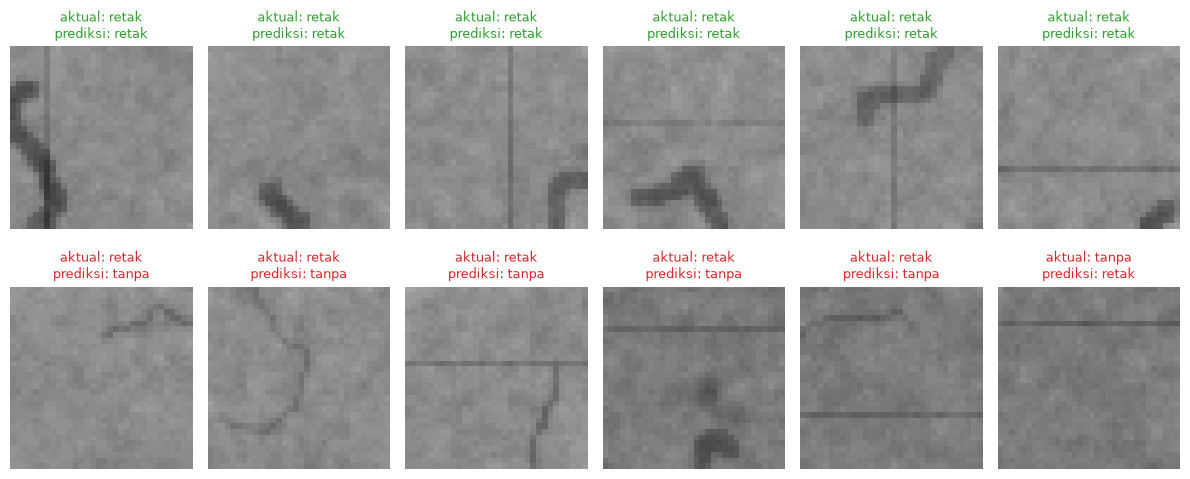

In [12]:
yp = prediksi_kelas(cnn, te); tebak = dict(zip(te, yp))
benar, salah = te[yp == yi[te]], te[yp != yi[te]]
fig, ax = plt.subplots(2, 6, figsize=(12, 5.2))
for a_, i in zip(ax.ravel(), list(benar[:6]) + list(salah[:6])):
    a_.imshow(d["X"][i], cmap="gray", vmin=0, vmax=255); a_.axis("off")
    ok = tebak[i] == yi[i]
    a_.set_title(f"aktual: {'retak' if yi[i] else 'tanpa'}\nprediksi: {'retak' if tebak[i] else 'tanpa'}", fontsize=9, color="tab:green" if ok else "tab:red")
plt.tight_layout(); plt.show()

Pembagian acak per citra dibandingkan dengan pembagian per panel.


In [13]:
rng_ = np.random.default_rng(SEED); semua = rng_.permutation(len(Xi)); n = len(semua)
tr_a, va_a, te_a = semua[:int(.6*n)], semua[int(.6*n):int(.8*n)], semua[int(.8*n):]
cnn_a, _ = latih_klasifikasi(CNNKecil, tr_a, va_a, SEED)
print("CNN, uji acak     : akurasi", round(accuracy_score(yi[te_a], prediksi_kelas(cnn_a, te_a)), 3),
      "| panel uji yang juga ada di data latih:", len(set(panel[te_a]) & set(panel[tr_a])), "dari", len(set(panel[te_a])))
print("CNN, uji per panel: akurasi", round(accuracy_score(yi[te], prediksi_kelas(cnn, te)), 3),
      "| panel uji yang juga ada di data latih:", len(set(panel[te]) & set(panel[tr])), "dari", len(set(panel[te])))

CNN, uji acak     : akurasi 0.902 | panel uji yang juga ada di data latih: 60 dari 60
CNN, uji per panel: akurasi 0.9 | panel uji yang juga ada di data latih: 0 dari 12


Variasi antarbenih untuk CNN.


In [14]:
hb = [ringkas(yi[te], prediksi_kelas(latih_klasifikasi(CNNKecil, tr, va, SEED+s)[0], te)) for s in range(5)]
hb = pd.DataFrame(hb); print("CNN, 5 benih acak (rerata ± simpangan baku):"); print(pd.DataFrame({"rerata": hb.mean(), "sd": hb.std()}).round(3))

CNN, 5 benih acak (rerata ± simpangan baku):
         rerata     sd
akurasi   0.896  0.020
presisi   0.944  0.025
recall    0.856  0.040
F1        0.897  0.022


**Catatan batas.** Citra sintetis ini sederhana dan dibuat dengan aturan yang diketahui; hasil CNN tidak dapat dibaca sebagai kemampuan mendeteksi retak pada citra lapangan. Pada data ini pembagian acak dan pembagian per panel memberi akurasi yang hampir sama karena pola panel tidak berkaitan dengan label; pada data nyata kebocoran semacam itu dapat menaikkan skor secara tidak jujur, sehingga unit kelompok tetap perlu dipakai.
